#### About

This file is used to make the predictions on all the splits for all 3 models. This predictions are saved in a seperate file to use for visualizations, to not recompute it all the time.

### Load data

In [1]:
import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import plotly.express as px
import plotly.graph_objects as go

from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.decomposition import TruncatedSVD
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay


with np.load("../data/bloodmnist.npz", allow_pickle=False) as dataset:
    t_images = dataset["train_images"]
    t_labels = dataset["train_labels"].reshape(-1)
    test_images = dataset["test_images"]
    test_labels = dataset["test_labels"].reshape(-1)

train_pred = pd.read_csv("../predictions/old_pred/bloodmnist_train_[AUC]1.000_[ACC]0.998@resnet50_224_1.csv", header=None)
train_pred = train_pred.to_numpy()
train_pred_resnet_50 = np.argmax(train_pred[:,1:], axis=1)

models = ["vit", "resnet18", "resnet50"]
augmentations = {"no_aug": "", "rotation": "_rot", "crop": "_crop"}
test_predictions = {}

for m in models:
    test_predictions[m] = {}
    for name, aug in augmentations.items():
        filename = f"../predictions/{m}_bloodmnist_test{aug}.csv"
        data = pd.read_csv(filename, header=None).to_numpy()
        test_pred = np.argmax(data[:,1:], axis=1)
        test_predictions[m][name] =  test_pred


# Visualizations

### Inspect train data

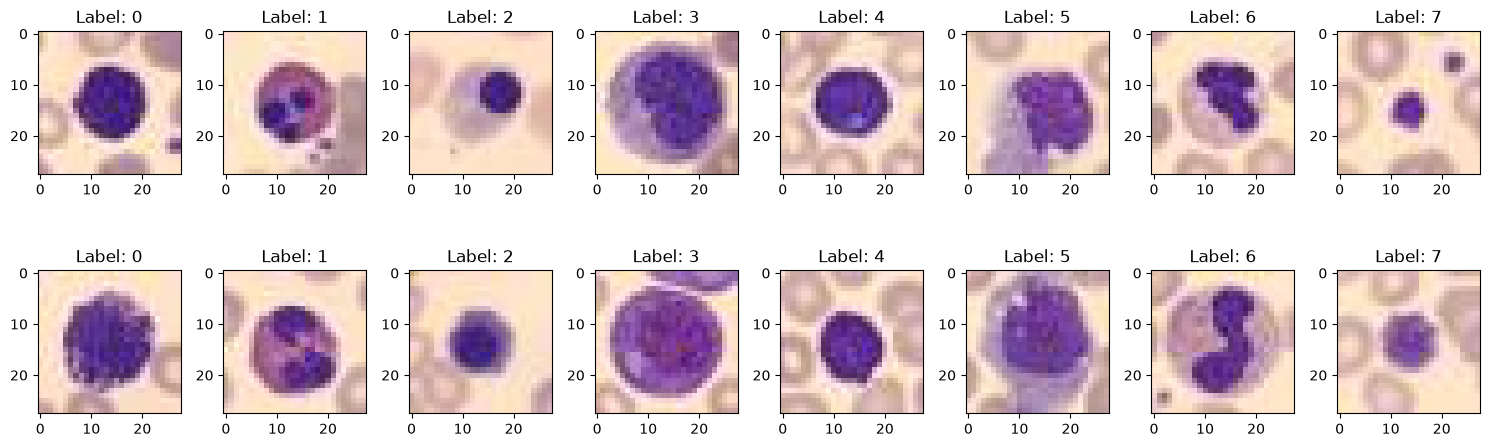

(11959, 28, 28, 3)


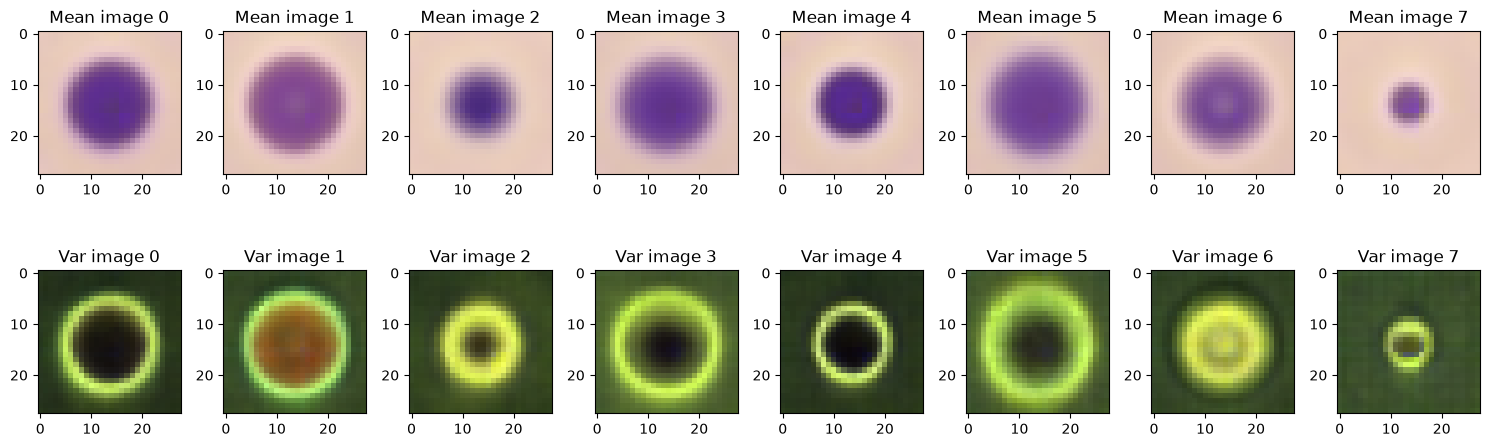

In [2]:
# sample images, mean+var, labels dist

fig, axes = plt.subplots(2,8,figsize=(15,5))
for i in range(8): 
    class_img = t_images[t_labels==i]
    axes[0,i].imshow(class_img[0])
    axes[0,i].title.set_text(f"Label: {i}")
    axes[1,i].imshow(class_img[1])
    axes[1,i].title.set_text(f"Label: {i}")

plt.tight_layout()
plt.show()


print(t_images.shape)

fig, axes = plt.subplots(2,8,figsize=(15,5))
for i in range(0,8):
    class_img = t_images[t_labels==i]
    mean_image = np.mean(class_img, axis=(0,), dtype=np.int64) 
    var_image = np.var(class_img, axis=(0,), dtype=np.int64) 
    var_image = var_image/np.max(var_image)
    axes[0,i].imshow(mean_image)
    axes[0,i].title.set_text(f"Mean image {i}")    
    axes[1,i].imshow(var_image)
    axes[1,i].title.set_text(f"Var image {i}")   

plt.tight_layout()
plt.show()


true_labels = np.bincount(test_labels)
pred_labels = np.bincount(test_predictions["resnet18"]["no_aug"])
df = pd.DataFrame({"Class": np.arange(8), "True labels": true_labels, "Predicted labels": pred_labels})
fig = px.bar(df,x="Class", y=["True labels", "Predicted labels"],barmode="group")
fig.show()

### Inspect misclassifications

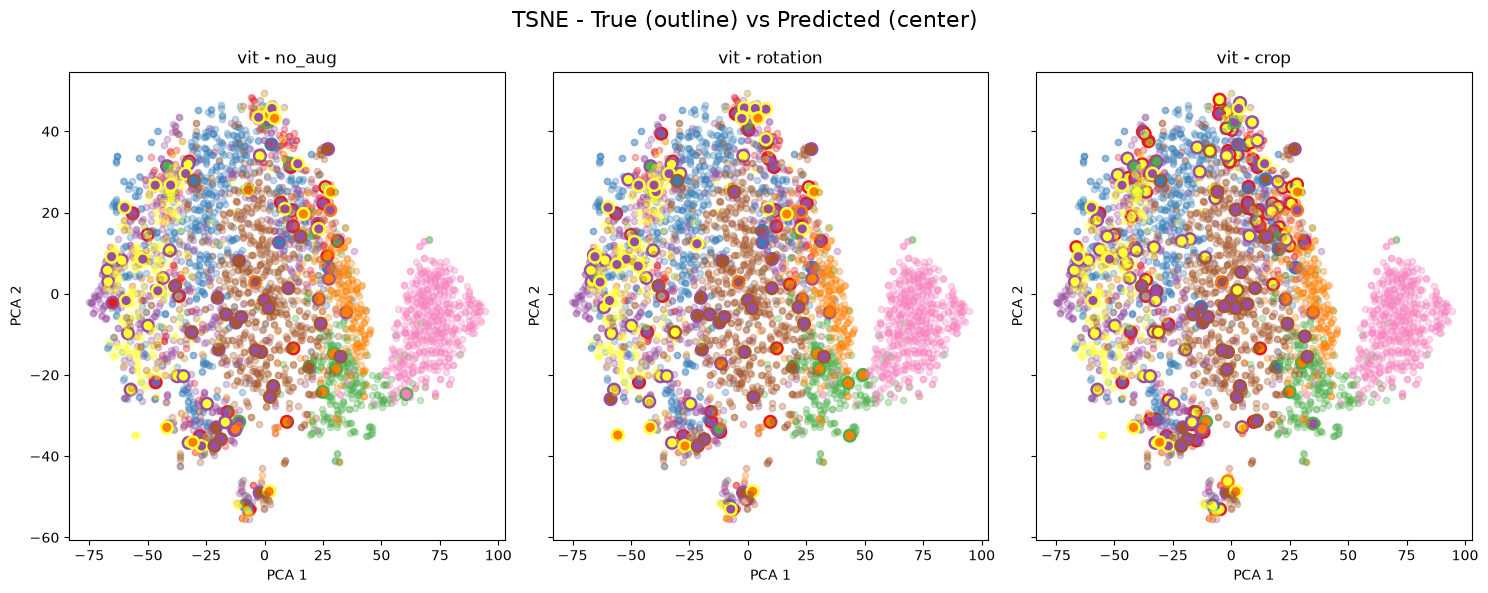

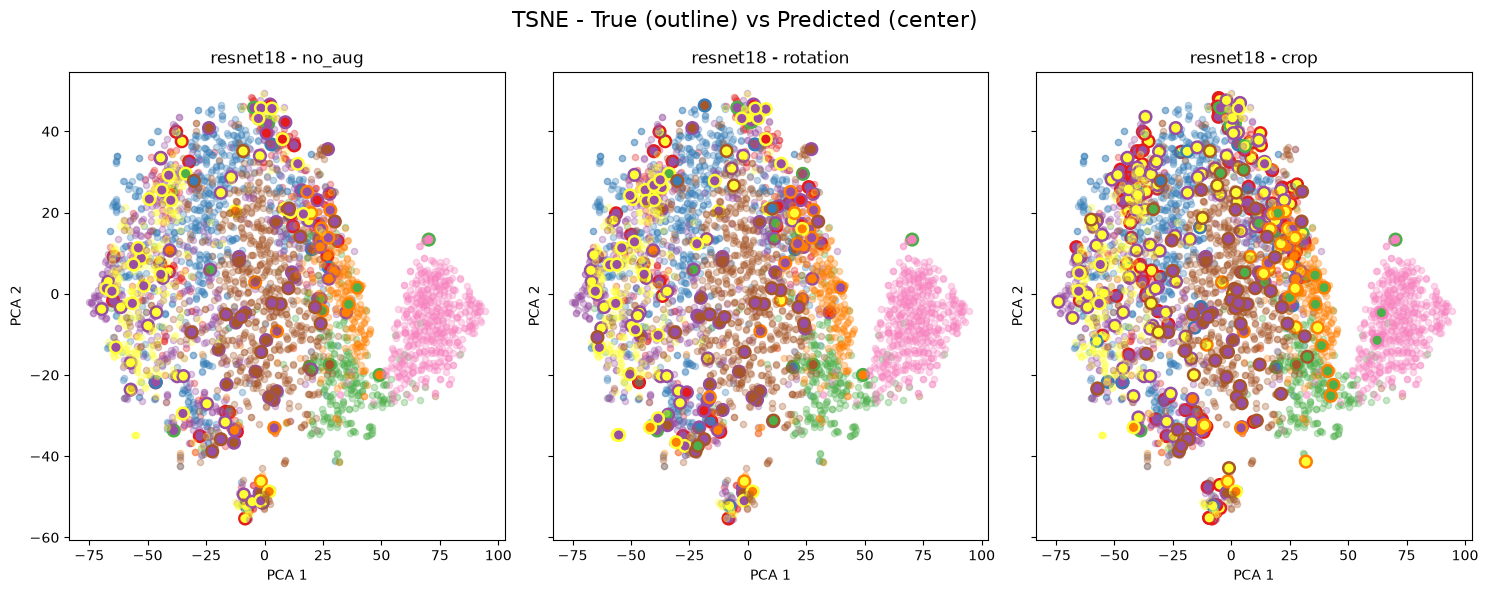

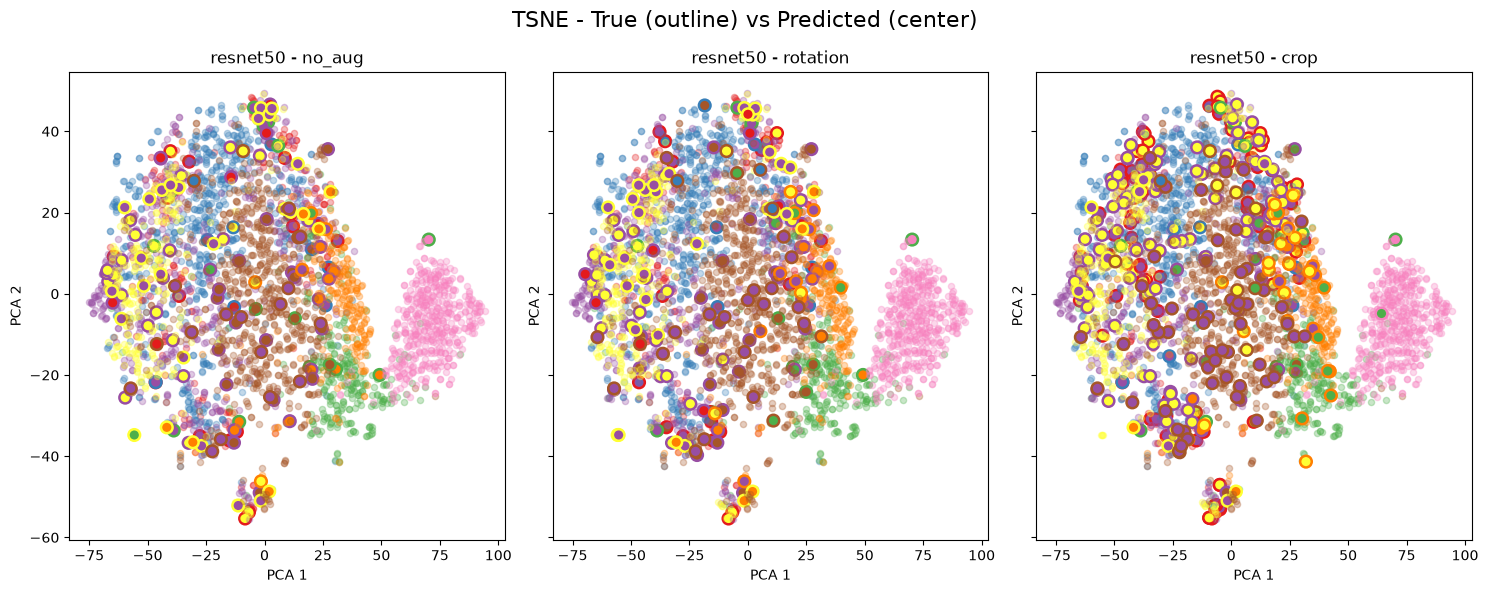

'fig = go.Figure()\n\nfig.add_scatter(x=test_pca[correctly_classified][:, 0], y=test_pca[correctly_classified][:, 1], legendgroup=0, name="correct", mode="markers", marker=dict(color="green"))\nfig.add_scatter(x=test_pca[misclassified][:, 0], y=test_pca[misclassified][:, 1], mode="markers", legendgroup=1, name = "misclassified", marker=dict(color="red" ,))\nfig.update_layout(title="PCA - correctly vs incorrectly classified", width=1000, height=700, legend=dict(groupclick="togglegroup"))\nfig.show()'

In [ ]:
pca = PCA(n_components=2)
test_pca = pca.fit_transform(test_images.reshape((test_images.shape[0], -1)))
tsne = TSNE(n_components=2, perplexity=15)
test_tsne = tsne.fit_transform(test_images.reshape((test_images.shape[0], -1)))
tsvd = TruncatedSVD(n_components=2)
train_tsvd = tsvd.fit_transform(test_images.reshape((test_images.shape[0], -1)))

#choose which dim. reduction to use
#TODO: are different represntations better (I glaub TSNE is fost besser ois PCA)
test_reduction = test_tsne


#TODO: remove? since we have plots below?
"""misclassified = test_labels!=test_predictions["resnet50"]["no_aug"]
correctly_classified = test_labels==test_predictions["resnet50"]["no_aug"]

norm = plt.Normalize(vmin=test_labels.min(), vmax=test_labels.max())
plt.figure(figsize=(12, 8))
scatter=plt.scatter(test_pca[:,0], test_pca[:,1], c=test_labels, alpha=0.5, cmap="Set1", s=20, norm=norm)

plt.title("PCA plot train")
handles, labels = scatter.legend_elements()
plt.legend(handles, labels, title="Classes")
plt.tight_layout()
plt.show()"""


#plotly PCA with wrong predictions
colors = dict(zip(np.arange(8), px.colors.qualitative.Set1))
"""fig = go.Figure()

for c in np.arange(8):
    fig.add_scatter(x=test_pca[test_labels==c][:, 0], y=test_pca[test_labels==c][:, 1], mode="markers", name=str(c), legendgroup=str(c), marker=dict(color=colors[c], size=6, opacity=0.4))
    fig.add_scatter(x=test_pca[(test_labels==c) & misclassified][:, 0], y=test_pca[(test_labels==c) & misclassified][:, 1],
        mode="markers", legendgroup=str(c), showlegend=False, marker=dict(color=[colors[p] for p in test_predictions["resnet50"]["no_aug"][(test_labels==c) & misclassified]],size=10,line=dict(color=colors[c], width=2)))
fig.update_layout(title="PCA - True (outline) vs Predicted (center)", width=1000, height=700, legend=dict(groupclick="togglegroup"))
fig.show()"""
cmap = plt.get_cmap("Set1")
colors = dict(zip(np.arange(8), [cmap(i) for i in range(8)]))



for i, model in enumerate(models):
    fig, axes = plt.subplots(1, len(augmentations), figsize=(15, 6), sharex=True, sharey=True)
    for j, aug in enumerate(augmentations):
        ax = axes[j]

        preds = test_predictions[model][aug]
        misclassified = test_labels != preds

        for c in np.arange(8):
            ax.scatter(x=test_reduction[test_labels==c][:, 0], y=test_reduction[test_labels==c][:, 1], color=colors[c], s=20, alpha=0.3)
            pred_classes = preds[(test_labels==c) & misclassified]
            face_colors = [colors[p] for p in pred_classes]
            ax.scatter(test_reduction[(test_labels==c) & misclassified][:, 0],test_reduction[(test_labels==c) & misclassified][:, 1],
                       s=70,facecolors=face_colors,edgecolors=colors[c], linewidths=1.8)

        ax.set_title(f"{model} - {aug}")
        ax.set_xlabel("PCA 1")
        ax.set_ylabel("PCA 2")


    fig.suptitle("TSNE - True (outline) vs Predicted (center)", fontsize=16)
    plt.tight_layout()
    plt.show()


#TODO: remove? since plot below
"""fig = go.Figure()

fig.add_scatter(x=test_pca[correctly_classified][:, 0], y=test_pca[correctly_classified][:, 1], legendgroup=0, name="correct", mode="markers", marker=dict(color="green"))
fig.add_scatter(x=test_pca[misclassified][:, 0], y=test_pca[misclassified][:, 1], mode="markers", legendgroup=1, name = "misclassified", marker=dict(color="red" ,))
fig.update_layout(title="PCA - correctly vs incorrectly classified", width=1000, height=700, legend=dict(groupclick="togglegroup"))
fig.show()"""


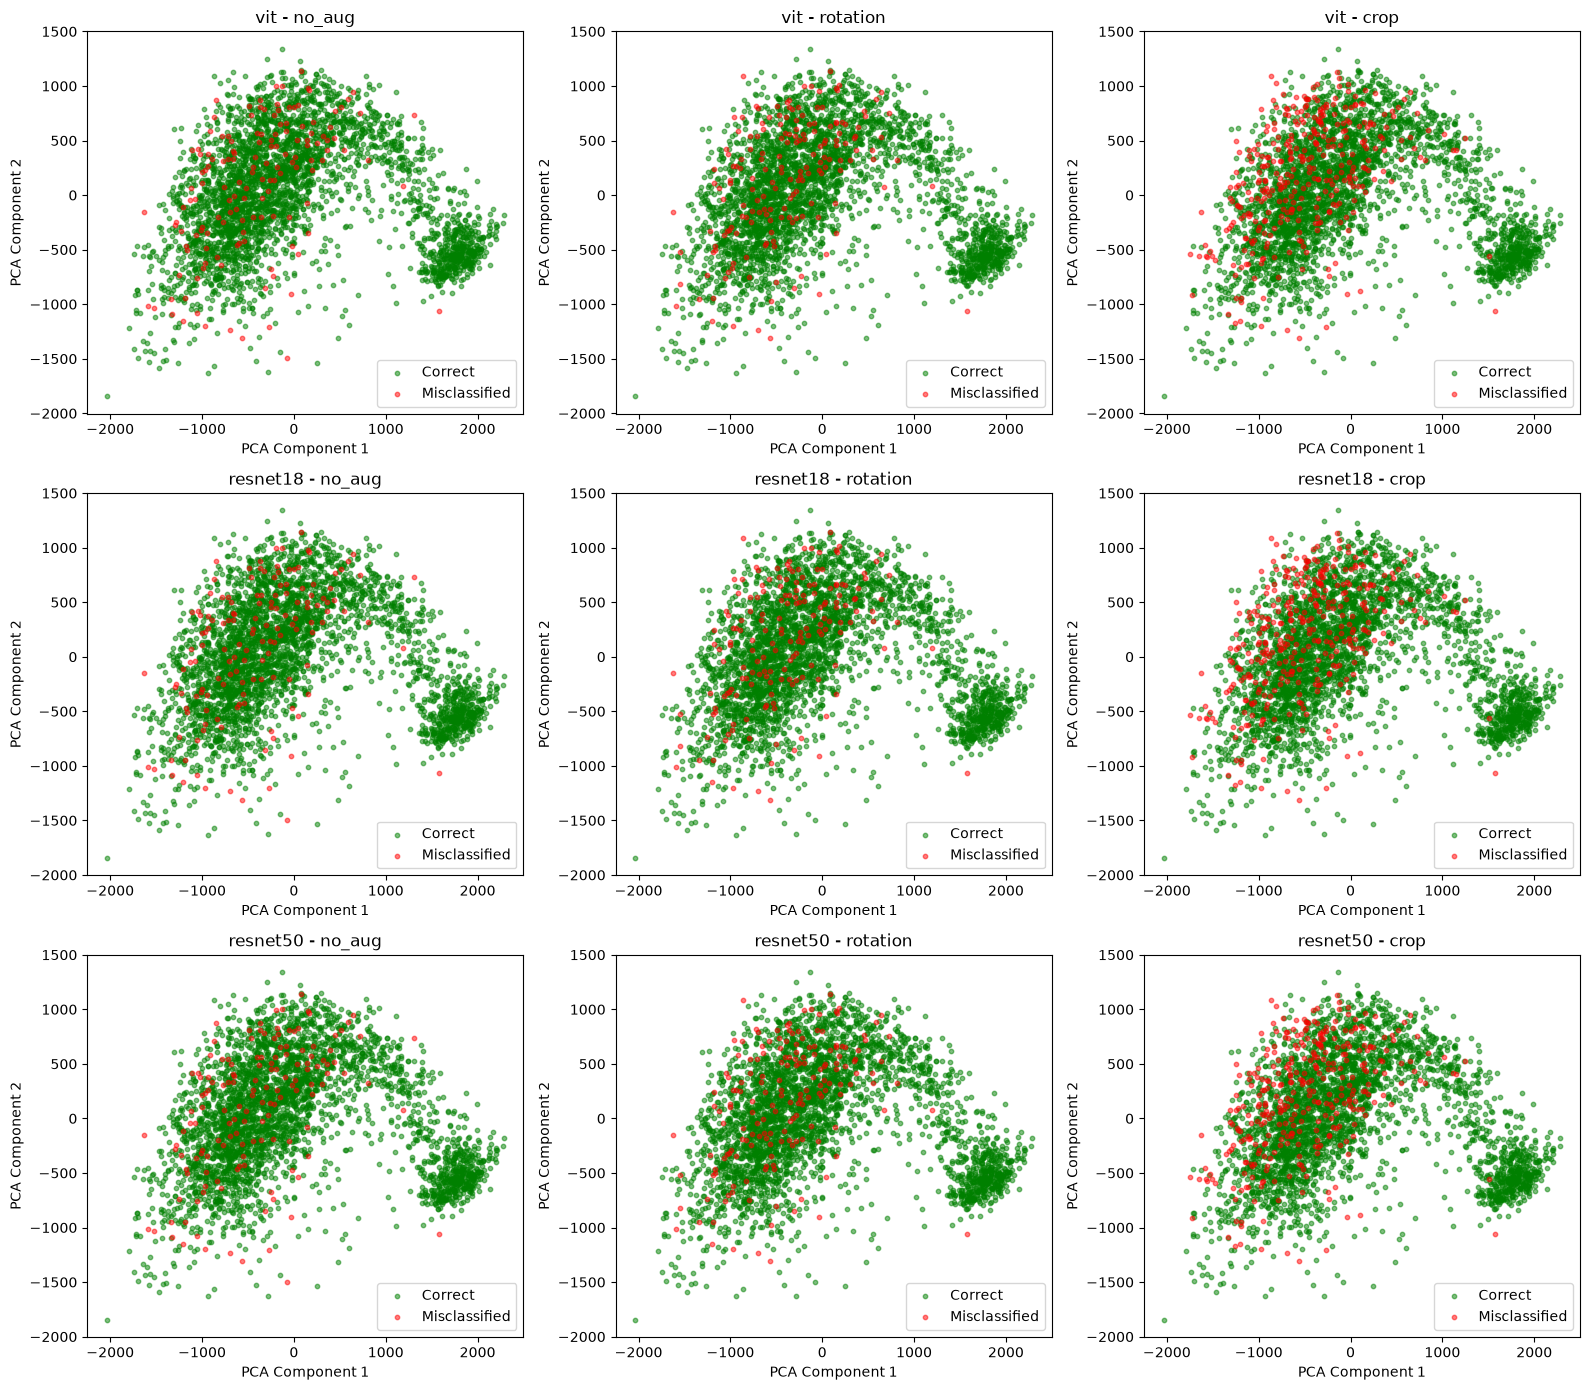

In [4]:
#plotly PCA with wrong predictions with out class coloring
models = ["vit", "resnet18", "resnet50"]
augmentations = ["no_aug", "rotation", "crop"]

fig, axes = plt.subplots(3, 3, figsize=(16, 14))

for i, model in enumerate(models):
    for j, aug in enumerate(augmentations):
        misclassified = test_labels!=test_predictions[m][aug]
        correctly_classified = test_labels==test_predictions[m][aug]
        axes[i, j].scatter(x=test_reduction[correctly_classified][:, 0], y=test_reduction[correctly_classified][:, 1], c="green", label="Correct", alpha=0.5, s=10)
        axes[i, j].scatter(x=test_reduction[misclassified][:, 0], y=test_reduction[misclassified][:, 1], c="red", label="Misclassified", alpha=0.5, s=10)
        axes[i, j].set_title(f"{model} - {aug}")
        axes[i, j].set_xlabel("PCA Component 1")
        axes[i, j].set_ylabel("PCA Component 2")
        axes[i, j].legend()

plt.tight_layout()
plt.show()

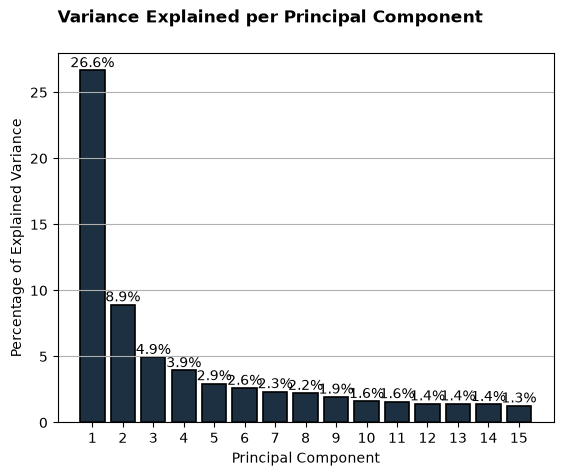

In [5]:
# using https://towardsdatascience.com/5-pca-visualizations-you-must-try-on-your-next-data-science-project-148ec3d31e4d/ 
# for input data inspection --> not useable for model behavior

pca = PCA(n_components=15)
train_pca = pca.fit(test_images.reshape((test_images.shape[0], -1)))
plot_y = [val * 100 for val in train_pca.explained_variance_ratio_]
plot_x = range(1, len(plot_y) + 1)

bars = plt.bar(plot_x, plot_y, align="center", color="#1C3041", edgecolor="#000000", linewidth=1.2)
for bar in bars:
    yval = bar.get_height()
    plt.text(bar.get_x() + bar.get_width() / 2, yval + 0.001, f"{yval:.1f}%", ha="center", va="bottom")

plt.xlabel("Principal Component")
plt.ylabel("Percentage of Explained Variance")
plt.title("Variance Explained per Principal Component", loc="left", fontdict={"weight": "bold"}, y=1.06)
plt.grid(axis="y")
plt.xticks(plot_x)

plt.show()

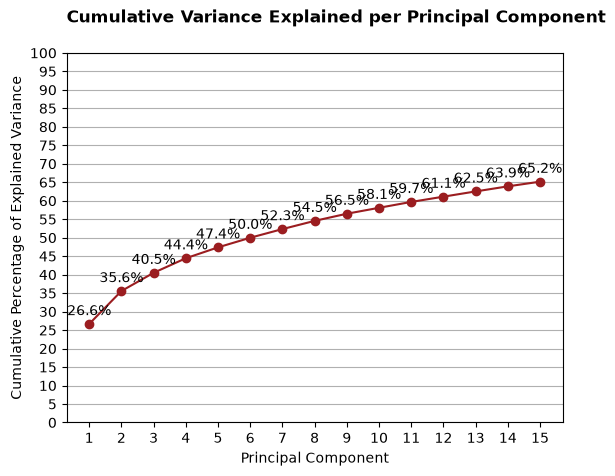

In [6]:
exp_var = [val * 100 for val in train_pca.explained_variance_ratio_]
plot_y = [sum(exp_var[:i+1]) for i in range(len(exp_var))]
plot_x = range(1, len(plot_y) + 1)

plt.plot(plot_x, plot_y, marker="o", color="#9B1D20")
for x, y in zip(plot_x, plot_y):
    plt.text(x, y + 1.5, f"{y:.1f}%", ha="center", va="bottom")

plt.xlabel("Principal Component")
plt.ylabel("Cumulative Percentage of Explained Variance")
plt.title("Cumulative Variance Explained per Principal Component", loc="left", fontdict={"weight": "bold"}, y=1.06)

plt.yticks(range(0, 101, 5))
plt.grid(axis="y")
plt.xticks(plot_x)

plt.show()

#### Confusion matrix

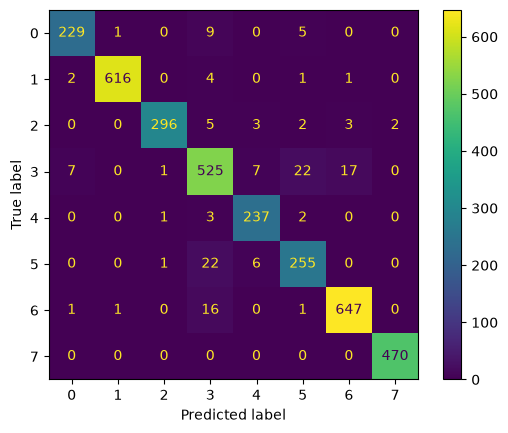

In [7]:
cm = confusion_matrix(test_labels, test_predictions["resnet50"]["no_aug"])

disp = ConfusionMatrixDisplay(confusion_matrix=cm)
disp.plot()
plt.show()

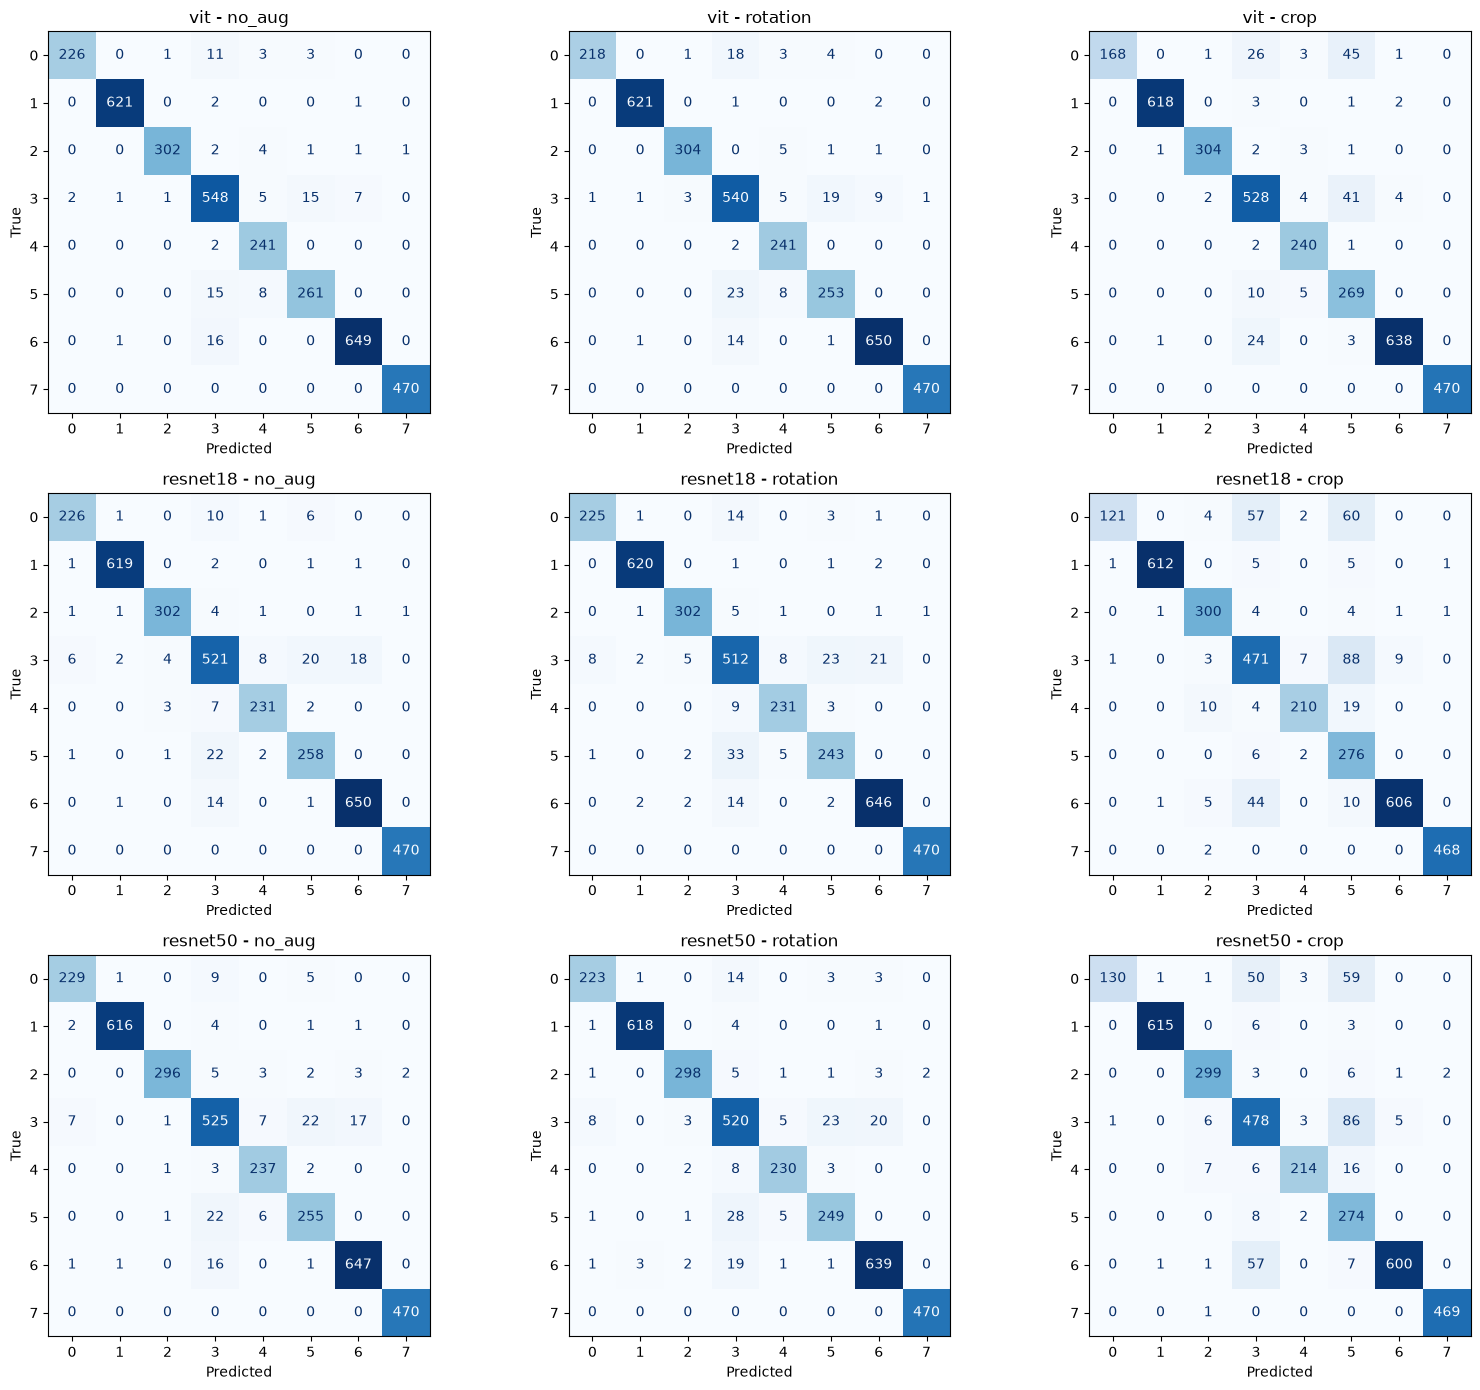

In [8]:
models = ["vit", "resnet18", "resnet50"]
augmentations = ["no_aug", "rotation", "crop"]

fig, axes = plt.subplots(3, 3, figsize=(16, 14))

for i, model in enumerate(models):
    for j, aug in enumerate(augmentations):
        y_pred = test_predictions[model][aug]
        cm = confusion_matrix(test_labels, y_pred)

        disp = ConfusionMatrixDisplay(confusion_matrix=cm)

        disp.plot(ax=axes[i, j],cmap="Blues",colorbar=False)

        axes[i, j].set_title(f"{model} - {aug}")
        axes[i, j].set_xlabel("Predicted")
        axes[i, j].set_ylabel("True")

plt.tight_layout()
plt.show()

### Inspect accuracies with data aug

In [9]:
accuracy_table = pd.DataFrame(index=models, columns=augmentations)

for m in models:
    for aug in augmentations:
        y_pred = test_predictions[m][aug]
        accuracy_table.loc[m, aug] = np.mean(y_pred == test_labels)

accuracy_table = accuracy_table.astype(float)

df_plot = accuracy_table.reset_index().melt(
    id_vars="index",
    var_name="Augmentation",
    value_name="Accuracy"
).rename(columns={"index": "Model"})

fig = px.bar(df_plot,x="Model", y="Accuracy", color="Augmentation", barmode="group", text_auto=".2%", title="Model Accuracy by Data Augmentation")
fig.update_traces(textposition="outside")
fig.update_layout(yaxis_range=[0, 1.05], legend_title="Augmentation")

fig.show()